# A1-1 — 쇼핑몰 고객 분석

목표는 데이터 탐색 → 결측치 처리 → 텍스트·이미지 피처 → IQR → 통계·6종 차트 → 고객 세분화다.
기본 입력은 **seed=42로 생성한 합성 거래·상품·RGB 배열**이다. 실제 고객이나 실제 상품 사진을 수집한 자료가 아니다.
아래 수치와 전략은 계산을 설명하는 예시이며, 실제 시장 효과를 검증한 결과가 아니다.
첫 실행은 저장소 루트에서 `python -m src.run_analysis --generate-sample`로 데이터를 만든다.
이 노트북은 그 입력을 읽으며 데이터가 없다고 임의로 생성하거나 외부 데이터를 덮어쓰지 않는다.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "pipeline.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "pipeline.py").is_file():
    raise RuntimeError("저장소 루트 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(ROOT))
from src.pipeline import DataAnalyzer
from src.report import write_report, statistical_interpretation, business_insights

DATA = ROOT / "data" / "sample"
OUTPUT = ROOT / "results"
analyzer = DataAnalyzer(DATA / "transactions.csv")


## 1. 데이터 로드와 기본 탐색

한 행은 주문 한 건이 아니라 **주문 안의 상품 한 줄**이다. 상품 테이블은 상품당 한 행이며 `product_id`로 연결한다.
`image_index`는 별도 NumPy 배열의 상품 축 위치다. 관계와 금액을 먼저 검사해 잘못된 조인이나 중복 주문 집계를 막는다.


In [2]:
df = analyzer.load_data()
display(df.head())
df.info()
display(df.describe())
display(Markdown(
    f"입력은 **{len(df):,}행·{len(df.columns)}컬럼**, "
    f"**{df.order_id.nunique():,}개 주문·{df.customer_id.nunique()}명 고객**이다. "
    "거래 행 수와 주문 수가 다르므로 Frequency에 행 수를 쓰면 구매 횟수가 과대 계산된다. "
    "수치·문자/범주·날짜형을 포함하고 상품 이미지 배열도 별도로 연결되어 있다."
))


,line_id,order_id,customer_id,order_date,product_id,unit_price,quantity,amount,country,payment_method,shipping_days,product_name,category,catalog_price,rating,image_index
0,L00000,O00000,C000,2026-04-26,P063,69600.0,4,278400.0,KR,Card,4.0,Electronics sample item 063,Electronics,69600.0,3.2,63
1,L00001,O00000,C000,2026-04-26,P071,24900.0,3,74700.0,KR,Transfer,4.0,Electronics sample item 071,Electronics,24900.0,3.9,71
2,L00002,O00000,C000,2026-04-26,P078,71400.0,1,71400.0,KR,Wallet,2.0,NaN,Electronics,71400.0,2.8,78
3,L00003,O00001,C000,2026-06-01,P074,53400.0,4,213600.0,US,Card,1.0,Electronics sample item 074,Electronics,53400.0,3.2,74
4,L00004,O00001,C000,2026-06-01,P065,78900.0,3,236700.0,KR,Wallet,6.0,Electronics sample item 065,Electronics,78900.0,NaN,65


<class 'pandas.DataFrame'>
RangeIndex: 2842 entries, 0 to 2841
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   line_id         2842 non-null   string        
 1   order_id        2842 non-null   string        
 2   customer_id     2842 non-null   string        
 3   order_date      2842 non-null   datetime64[us]
 4   product_id      2842 non-null   string        
 5   unit_price      2842 non-null   float64       
 6   quantity        2842 non-null   int64         
 7   amount          2842 non-null   float64       
 8   country         2842 non-null   str           
 9   payment_method  2842 non-null   str           
 10  shipping_days   2570 non-null   float64       
 11  product_name    2528 non-null   str           
 12  category        2842 non-null   str           
 13  catalog_price   2411 non-null   float64       
 14  rating          2557 non-null   float64       
 15  image_index    

,order_date,unit_price,quantity,amount,shipping_days,catalog_price,rating,image_index
count,2842,2842.000000,2842.000000,2842.000000,2570.000000,2411.000000,2557.000000,2842.000000
mean,2026-07-28 17:58:43.997185,40497.079521,2.470443,100352.638987,4.871595,38562.671091,3.699726,56.383533
min,2026-01-11 00:00:00,5100.000000,1.000000,5100.000000,1.000000,5100.000000,2.600000,0.000000
25%,2026-06-28 00:00:00,21100.000000,1.000000,39900.000000,3.000000,20650.000000,3.200000,45.000000
50%,2026-08-17 00:00:00,37800.000000,2.000000,75000.000000,5.000000,37200.000000,3.700000,64.000000
75%,2026-09-09 00:00:00,54000.000000,3.000000,148650.000000,7.000000,54000.000000,4.300000,72.000000
max,2026-10-09 00:00:00,81900.000000,4.000000,327600.000000,60.000000,81900.000000,4.900000,79.000000
std,NaN,22539.121027,1.121298,76630.081377,4.789197,21663.838355,0.699924,21.767418


입력은 **2,842행·16컬럼**, **1,389개 주문·240명 고객**이다. 거래 행 수와 주문 수가 다르므로 Frequency에 행 수를 쓰면 구매 횟수가 과대 계산된다. 수치·문자/범주·날짜형을 포함하고 상품 이미지 배열도 별도로 연결되어 있다.

## 2. 결측치 현황과 카테고리별 대치

상품 가격·평점은 **상품 테이블에서** 카테고리별 중앙값으로 보완한다. 거래 테이블에서 계산하면 많이 팔린 상품에 가중치가 붙는다.
배송 일수는 거래 행의 카테고리별 중앙값을 사용한다. 그룹 전체가 비면 전체 중앙값으로 보완하며, 컬럼 전체가 비면 오류를 낸다.
이름 누락은 `Unknown product`로 명시한다. 고객 ID·거래일·거래 금액은 추정하지 않는다.


In [3]:
missing_before = analyzer.df.isna().sum()
analyzer.handle_missing_values(strategy="median", group_col="category")
display(pd.DataFrame({"before": missing_before, "after": analyzer.df.isna().sum()}))
display(Markdown(
    f"거래 행에서 보이는 결측치가 **{int(missing_before.sum())}개 → "
    f"{int(analyzer.df.isna().sum().sum())}개**로 변했다. "
    "이 개수는 판매 행 기준이고 실제 보완한 상품 속성 수는 audit의 product_values에서 별도로 확인한다. "
    "대치값은 실제 관측값이 아니므로 이후 통계 해석에 영향을 줄 수 있다."
))
display(analyzer.audit["imputation"])


,before,after
line_id,0,0
order_id,0,0
customer_id,0,0
order_date,0,0
product_id,0,0
unit_price,0,0
quantity,0,0
amount,0,0
country,0,0
payment_method,0,0


거래 행에서 보이는 결측치가 **1302개 → 0개**로 변했다. 이 개수는 판매 행 기준이고 실제 보완한 상품 속성 수는 audit의 product_values에서 별도로 확인한다. 대치값은 실제 관측값이 아니므로 이후 통계 해석에 영향을 줄 수 있다.

{'strategy': 'median',
 'group': 'category',
 'product_values': {'catalog_price': 12, 'rating': 7},
 'line_values': {'shipping_days': 272}}

## 3. 멀티 모달 피처 엔지니어링

RGB 배열의 형태는 `(상품 수, 높이, 너비, 채널 수)`다. 상품 축은 유지하고 나머지 축을 한 번에 평균·표준편차로 줄인다.
이미지나 픽셀을 순회하는 Python 반복문을 사용하지 않는다. 같은 상품의 통계는 거래 행에 다시 연결한다.
픽셀 평균은 밝기의 요약, 표준편차는 변동의 요약이다. 이미지의 의미나 상품 품질을 판단한 값은 아니다.
상품명에서는 문자 수와 공백 단위 단어 수를 계산한다.


In [4]:
analyzer.engineer_features()
display(analyzer.df[["product_id", "product_name", "name_length", "name_word_count", "image_mean", "image_std"]].head())
display(Markdown(
    f"이미지 배치 shape는 **{analyzer.images.shape}**이고, "
    f"거래 행의 평균 픽셀값 범위는 **{analyzer.df.image_mean.min():.2f}–{analyzer.df.image_mean.max():.2f}**다. "
    "밝기·픽셀 변동을 수치형 변수와 함께 분석할 수 있지만 실제 시각적 품질로 해석하지 않는다."
))


,product_id,product_name,name_length,name_word_count,image_mean,image_std
0,P063,Electronics sample item 063,27,4,105.790365,39.889647
1,P071,Electronics sample item 071,27,4,118.795573,61.300924
2,P078,Unknown product,15,2,120.574219,46.831755
3,P074,Electronics sample item 074,27,4,148.595052,49.990143
4,P065,Electronics sample item 065,27,4,138.708333,34.381073


이미지 배치 shape는 **(80, 16, 16, 3)**이고, 거래 행의 평균 픽셀값 범위는 **48.99–184.24**다. 밝기·픽셀 변동을 수치형 변수와 함께 분석할 수 있지만 실제 시각적 품질로 해석하지 않는다.

## 4. IQR 이상치 탐지와 처리 비교

`IQR = Q3 − Q1`, 경계는 `Q1 − 1.5×IQR`, `Q3 + 1.5×IQR`이다.
`detect_outliers()`는 표시하고, `treat_outliers()`는 비교용 Series를 반환한다. 원본 컬럼을 덮어쓰지 않는다.
배송 일수는 클리핑 전후를 박스플롯으로 비교한다. 고가 거래는 우수 고객의 정상 구매일 수 있어 RFM에서 삭제하지 않는다.


In [5]:
shipping_outliers = analyzer.detect_outliers("shipping_days", threshold=1.5)
price_outliers = analyzer.detect_outliers("unit_price", threshold=1.5)
treated_shipping = analyzer.treat_outliers("shipping_days", method="clip")
display(analyzer.audit["outliers"])
display(Markdown(
    f"배송 이상치 **{len(shipping_outliers)}행**, 단가 이상치 **{len(price_outliers)}행**을 표시했다. "
    f"배송 최댓값은 비교 처리 전 **{analyzer.df.shipping_days.max():.1f}일**, "
    f"처리 후 **{treated_shipping.max():.1f}일**이다. "
    "장기 배송이 실제 지연인지 기록 오류인지 판단하려면 배송 이력을 확인해야 한다."
))


{'shipping_days': {'threshold': 1.5,
  'lower': -1.5,
  'upper': 10.5,
  'count': 15},
 'unit_price': {'threshold': 1.5,
  'lower': -28250.0,
  'upper': 103350.0,
  'count': 0}}

배송 이상치 **15행**, 단가 이상치 **0행**을 표시했다. 배송 최댓값은 비교 처리 전 **60.0일**, 처리 후 **10.5일**이다. 장기 배송이 실제 지연인지 기록 오류인지 판단하려면 배송 이력을 확인해야 한다.

## 5. 요약 통계와 상관분석

평균·중앙값·표준편차·Q1·Q3를 함께 확인한다. 아래 통계는 거래 행 기준이므로 자주 팔린 상품이 더 많이 반영된다.
단가–금액, 수량–금액의 Pearson 상관을 계산한다. 금액은 단가×수량이므로 상관에는 계산식 자체의 영향이 있다.
반복 판매 때문에 행들이 독립 표본이라고 단정할 수 없으며, 상관계수는 인과 효과를 검증하지 않는다.


In [6]:
display(analyzer.summarize())
display(analyzer.df[["unit_price", "quantity", "amount", "shipping_days", "image_mean", "image_std"]].corr())
display(Markdown(statistical_interpretation(analyzer)))


,count,mean,std,min,25%,50%,75%,max
unit_price,2842.0,40497.079521,22539.121027,5100.000000,21100.000000,37800.000000,54000.000000,81900.000000
amount,2842.0,100352.638987,76630.081377,5100.000000,39900.000000,75000.000000,148650.000000,327600.000000
shipping_days,2842.0,4.873681,4.555174,1.000000,3.000000,5.000000,6.000000,60.000000
image_mean,2842.0,120.950887,23.973322,48.986979,104.877604,124.292969,139.040365,184.239583
image_std,2842.0,46.458466,10.842751,28.275060,37.673408,46.831755,52.631108,70.901374


,unit_price,quantity,amount,shipping_days,image_mean,image_std
unit_price,1.000000,0.012148,0.731093,0.004560,0.163730,-0.015595
quantity,0.012148,1.000000,0.605164,0.061670,-0.014545,-0.007916
amount,0.731093,0.605164,1.000000,0.040374,0.116111,-0.017253
shipping_days,0.004560,0.061670,0.040374,1.000000,0.017197,-0.012169
image_mean,0.163730,-0.014545,0.116111,0.017197,1.000000,-0.055536
image_std,-0.015595,-0.007916,-0.017253,-0.012169,-0.055536,1.000000


거래 행 기준 단가 평균 40497원, 중앙값 37800원, 표준편차 22539원, Q1 21100원, Q3 54000원이다. 평균·중앙값 차이와 히스토그램을 함께 봐야 고가 상품의 영향을 판단할 수 있다.

unit_price–amount Pearson r=0.731. amount=unit_price×quantity라는 계산 관계가 있으므로 독립적인 원인이나 마케팅 효과의 증거로 해석하지 않는다.

quantity–amount Pearson r=0.605. amount=unit_price×quantity라는 계산 관계가 있으므로 독립적인 원인이나 마케팅 효과의 증거로 해석하지 않는다.

## 6. RFM과 고객 세분화

- Recency: 기준일에서 마지막 유효 구매일까지 지난 날짜 수. 기본 기준일은 최종 거래일 다음 날이다.
- Frequency: 관측 기간 전체의 고유 주문 수. 한 주문의 상품 행을 여러 번 세지 않는다.
- Monetary: 유효한 양수 구매 금액의 합계. 반품 차감 순매출이나 평생가치(LTV)가 아니다.

각 지표를 평균 순위의 백분위로 1–5점화한다. R은 작을수록 높은 점수이며 동점에는 같은 점수를 준다.
상호 배타적인 그룹 규칙은 다음 순서다. 점수 합 자체로 그룹을 정하지 않는다.

1. Inactive: R > 90일. 실제 이탈 확정이 아니라 구매 공백 표시다.
2. New: R ≤ 30일이고 F = 1회.
3. VIP: R ≤ 30일, F ≥ 4회, M ≥ 전체 고객 M의 75백분위.
4. Loyal: 위 그룹에 해당하지 않고 F ≥ 4회.
5. Regular: 그 외.

기준은 학습용 정책이며 상품 구매 주기·분석 기간이 바뀌면 재검토한다.


In [7]:
rfm = analyzer.calculate_rfm()
segments = analyzer.segment_summary()
display(rfm.head())
display(segments.round(2))
display(Markdown(
    f"기준일 **{analyzer.audit['rfm']['reference_date']}**, 고객 **{len(rfm)}명**, "
    f"세그먼트 **{rfm.segment.nunique()}개**다. VIP 금액 기준은 "
    f"**{analyzer.audit['rfm']['vip_monetary_cutoff']:,.0f}원**이다. "
    "합성 고객 패턴을 의도적으로 구성했으므로 그룹이 나뉜다는 사실만으로 실제 고객에 대한 타당성이 입증되지는 않는다."
))


,recency,frequency,monetary,r_score,f_score,m_score,rfm_score,segment
customer_id,,,,,,,,
C000,11,14,4279800.0,3,5,5,13,VIP
C001,7,13,3917400.0,4,5,5,14,VIP
C002,13,13,3906600.0,3,5,5,13,VIP
C003,3,11,2688900.0,5,5,5,15,VIP
C004,3,10,2069100.0,5,4,4,13,VIP


,customers,mean_recency,mean_frequency,mean_monetary,revenue,customer_share_pct,revenue_share_pct
segment,,,,,,,
Inactive,60,171.93,3.15,459950.00,27597000.0,25.0,9.68
Loyal,60,27.52,5.92,772971.67,46378300.0,25.0,16.26
New,60,4.47,1.00,126613.33,7596800.0,25.0,2.66
VIP,60,8.33,13.08,3393835.00,203630100.0,25.0,71.40


기준일 **2026-10-10**, 고객 **240명**, 세그먼트 **4개**다. VIP 금액 기준은 **1,786,650원**이다. 합성 고객 패턴을 의도적으로 구성했으므로 그룹이 나뉜다는 사실만으로 실제 고객에 대한 타당성이 입증되지는 않는다.

## 7. 여섯 가지 시각화와 결과 저장

히스토그램(단가 분포), 박스플롯(배송 처리 전후), 막대그래프(그룹별 고객 수), 히트맵(상관행렬),
산점도(고객별 빈도–금액), 라인차트(월별 양수 구매 매출)를 저장한다. 모든 차트에 제목·축 이름이 있다.
월별 선 그래프는 데이터 생성 패턴과 관측 기간의 영향을 받으므로 실제 계절성으로 해석하지 않는다.


In [8]:
chart_paths = write_report(analyzer, OUTPUT)
print(f"표, audit, 해석 및 차트 저장: {OUTPUT}")


표, audit, 해석 및 차트 저장: C:\Users\alzznd\Desktop\newlearn\projects\codsaid\AI_SW\02_Advanced\A1-1\results


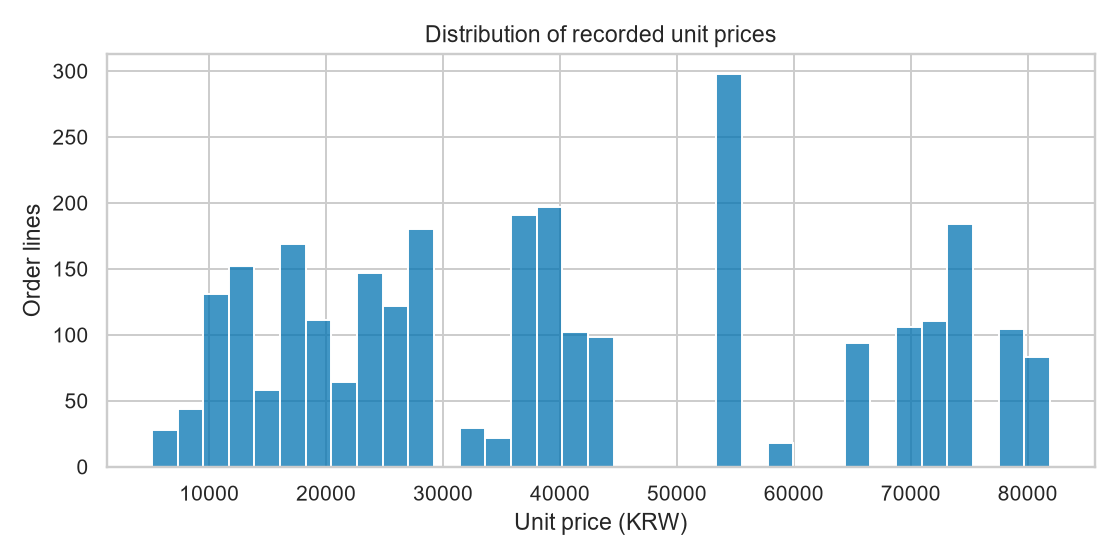

In [9]:
display(Image(filename=str(OUTPUT / "figures" / "01_histogram.png")))


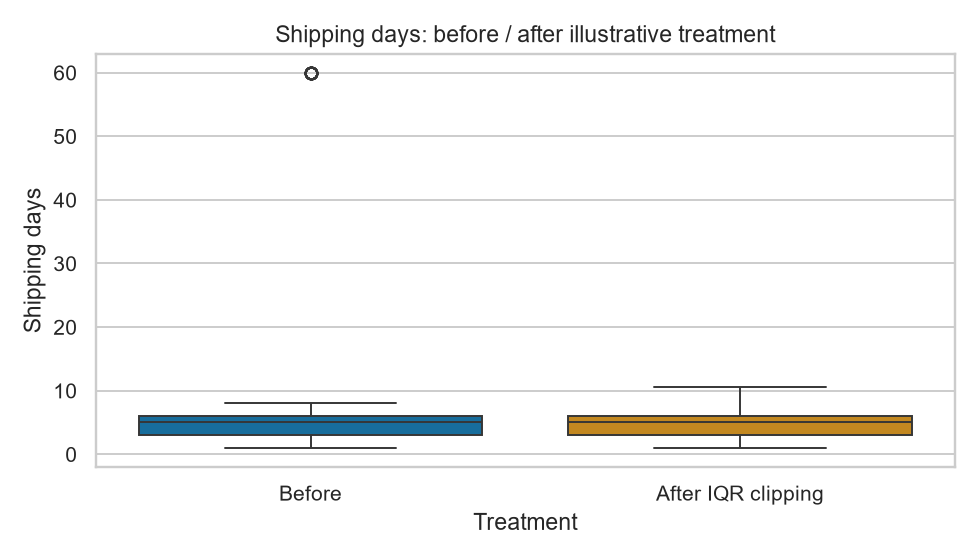

In [10]:
display(Image(filename=str(OUTPUT / "figures" / "02_boxplot.png")))


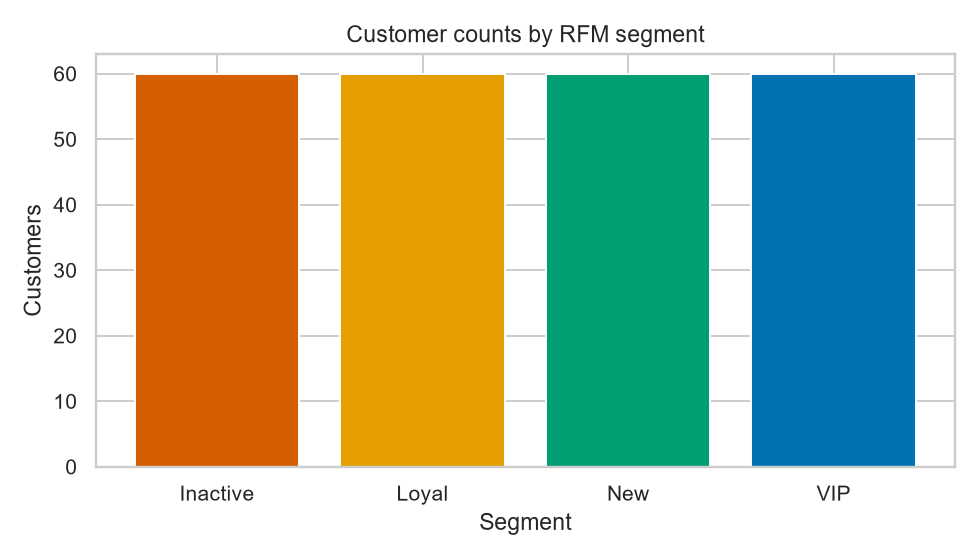

In [11]:
display(Image(filename=str(OUTPUT / "figures" / "03_bar.png")))


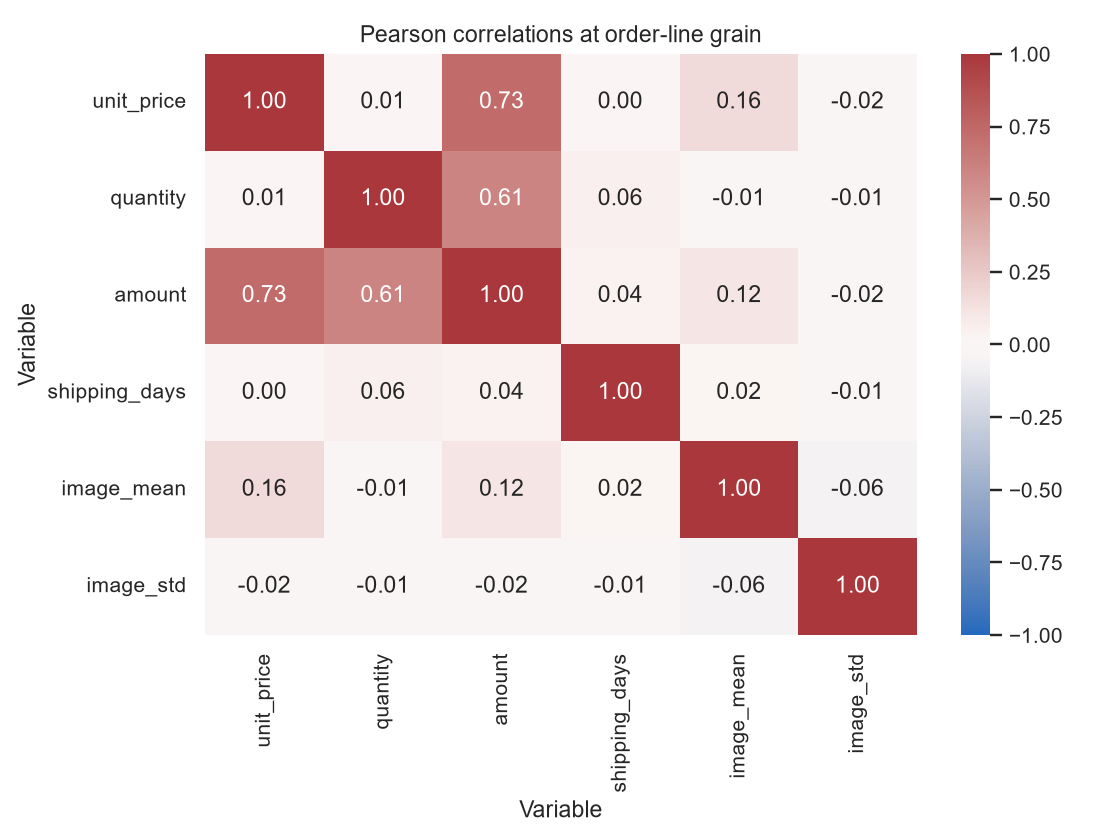

In [12]:
display(Image(filename=str(OUTPUT / "figures" / "04_heatmap.png")))


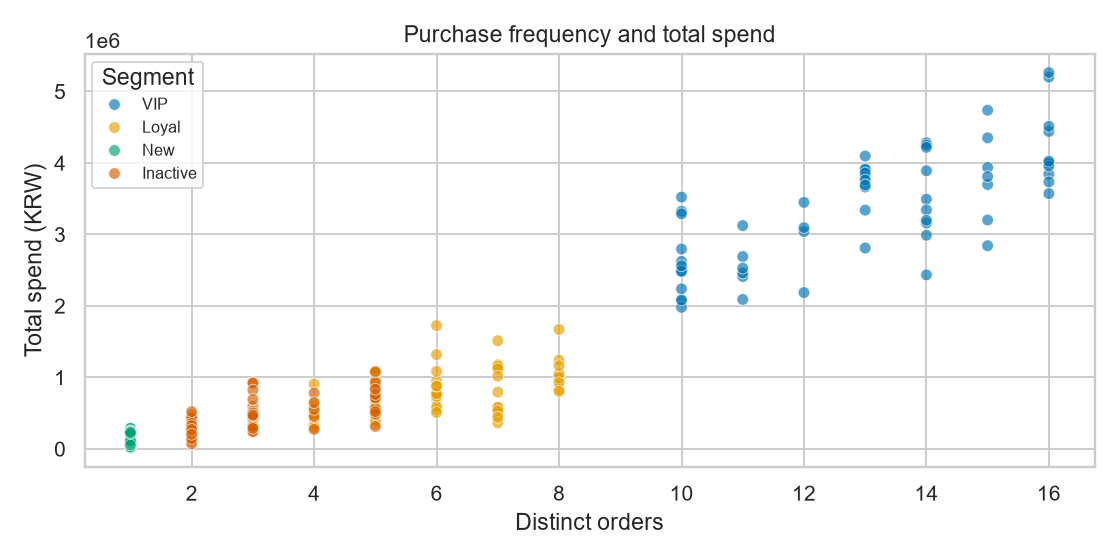

In [13]:
display(Image(filename=str(OUTPUT / "figures" / "05_scatter.png")))


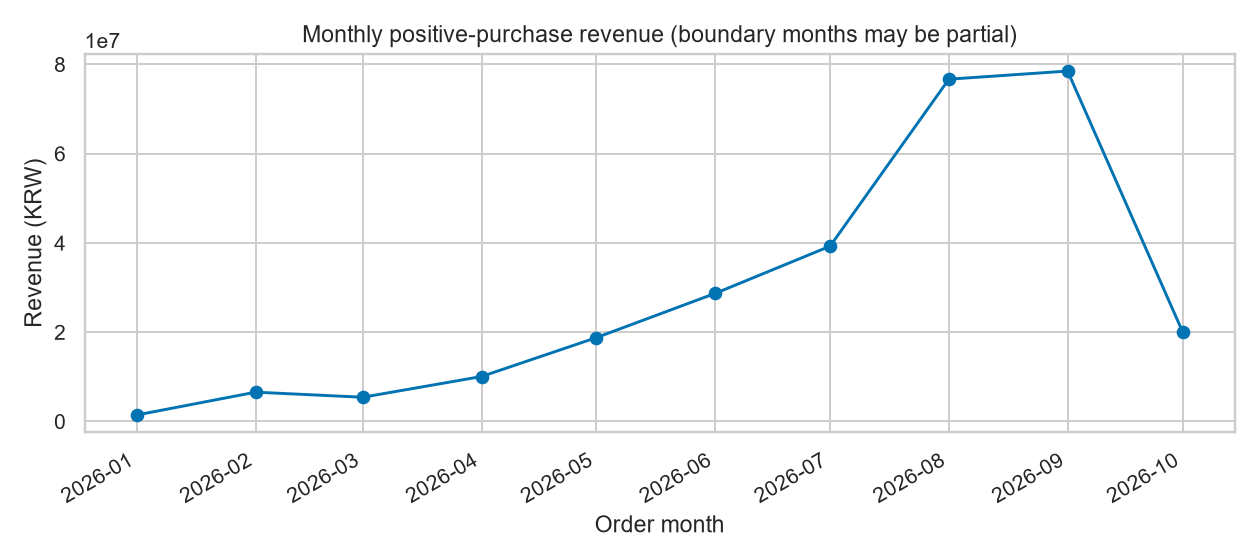

In [14]:
display(Image(filename=str(OUTPUT / "figures" / "06_line.png")))


## 8. 데이터 근거 → 실행 가설 → 검증 조건

아래 수치는 현재 실행 결과에서 계산한다. 기대 효과는 실험할 가설이며, 개선율을 측정한 것처럼 쓰지 않는다.


In [15]:
display(Markdown(business_insights(segments)))
assert len(analyzer.df) >= 1000
assert len(analyzer.df.columns) >= 8
assert rfm.segment.nunique() >= 4
assert len(chart_paths) == 6
print("기본 합성 데이터의 규모·세분화·차트 요구사항 확인 완료")


### VIP

- 근거: 고객 60명(25.0%), 매출 비중 71.4%, 평균 구매 횟수 13.08회, 평균 최근 구매 경과 8.3일. `segment_summary.csv`와 `03_bar.png`, `05_scatter.png` 참조.
- 실행: VIP 대상 → 멤버십 혜택을 소규모 대조군 실험으로 제공 → 기대 효과: 재구매 유지. 아직 검증하지 않은 가설이며 효과 크기를 측정하지 않았다.
- 검증: 혜택 비용과 대조군의 재구매율이 필요하다. 비용 증가가 추가 이익보다 크면 제안을 기각한다.

### Inactive

- 근거: 고객 60명(25.0%), 매출 비중 9.7%, 평균 구매 횟수 3.15회, 평균 최근 구매 경과 171.9일. `segment_summary.csv`와 `03_bar.png`, `05_scatter.png` 참조.
- 실행: Inactive 대상 → 최근 구매 간격을 확인하고 복귀 메시지를 대조군과 비교 → 기대 효과: 재구매 회복. 아직 검증하지 않은 가설이며 효과 크기를 측정하지 않았다.
- 검증: 품목별 정상 구매 주기와 수신 동의 정보가 필요하다. 긴 구매 주기가 정상이라면 이탈 해석을 수정한다.

### New

- 근거: 고객 60명(25.0%), 매출 비중 2.7%, 평균 구매 횟수 1.00회, 평균 최근 구매 경과 4.5일. `segment_summary.csv`와 `03_bar.png`, `05_scatter.png` 참조.
- 실행: New 대상 → 첫 구매 후 사용 안내와 다음 구매 추천을 대조군과 비교 → 기대 효과: 두 번째 구매 전환. 아직 검증하지 않은 가설이며 효과 크기를 측정하지 않았다.
- 검증: 첫 구매 후 동일한 추적 기간과 반품 정보가 필요하다. 전환율 차이가 없으면 추천 효과를 주장할 수 없다.

### Loyal

- 근거: 고객 60명(25.0%), 매출 비중 16.3%, 평균 구매 횟수 5.92회, 평균 최근 구매 경과 27.5일. `segment_summary.csv`와 `03_bar.png`, `05_scatter.png` 참조.
- 실행: Loyal 대상 → 반복 구매 품목의 재입고 알림을 대조군과 비교 → 기대 효과: 구매 편의 개선. 아직 검증하지 않은 가설이며 효과 크기를 측정하지 않았다.
- 검증: 재고와 알림 비용이 필요하다. 자연 재구매와 차이가 없으면 효과를 주장할 수 없다.


기본 합성 데이터의 규모·세분화·차트 요구사항 확인 완료


## 구현 근거와 범위

- `src/pipeline.py`: 분석·전처리·RFM. `tests/test_pipeline.py`: 주문 단위 집계, 동점, 결측치, 이미지 축, 이상치 보존 등의 검증.
- 데이터 출처: `src/sample_data.py`로 로컬 생성. 생성 조건: `data/sample/metadata.json`.
- 사용 라이브러리: NumPy, Pandas, Matplotlib, Seaborn. Notebook 도구는 실행·표시용이다. OpenCV·Pillow·Scikit-learn·NLTK를 직접 사용하지 않는다.
- 이미지 축 연산 참고: [NumPy mean 공식 문서](https://numpy.org/doc/stable/reference/generated/numpy.mean.html).
- HTML 학습 자료와 선택 보너스 과제는 이번 구현 범위에 포함하지 않는다.
